In [1]:
from scipy.io import loadmat
import mat73

from tqdm.notebook import tqdm

import numpy as np
import pandas as pd

from matplotlib import pyplot as plt
from matplotlib import colorbar as mbar
import seaborn as sns

from scipy.ndimage import gaussian_filter as smooth

from scipy.stats import zscore
from scipy.stats import sem
from scipy.stats import spearmanr as spearman

from scipy.stats import permutation_test

import warnings
warnings.filterwarnings('ignore')
from IPython.display import clear_output

# Definitions

In [2]:
def m_plot(input_data, colors, error_method='sem', smooth_win=0, labels=[], plot_title='', XAxisTicks=[], figure_size=(8,3)):
    '''
    Args:
        input_data:   (N,M,T) matrix of input data, (Conditions,Samples,Timepoints)
        colors:       (N,4) matrix of colors for the generated plots in [R,G,B,FaceAlpha] format,
                      where N is the number of conditions. FaceAlpha in the scale=[0-255]
        error_method: variation metric ('sem' & 'std')
        smooth_win:   smoothing window
        
        labels:       (N,) list of labels for the generated plots, where N is the number of conditions
        plot_title:   title of the generated plot
        XAxisTicks:   (N,) vaetor of XAxisTicks
        figure_size:  two-item tuple containing width and height of the figure
    Returns:
        none
    '''

    colors = np.array(colors) / np.array(255)
    if not labels: labels=['']*len(input_data)
    XAxisTicks = np.array(XAxisTicks)
    if XAxisTicks.size==0: XAxisTicks = np.arange(0,input_data[0].shape[1])
    
    plt.figure(figsize=figure_size)
    for i,Cond in enumerate(input_data):
        data_ave = smooth(np.nanmean(Cond, axis=0), smooth_win)
        data_std = smooth(np.nanstd(Cond, axis=0), smooth_win)
        
        if error_method=='sem':
            error_up  = data_ave + (data_std / np.sqrt(Cond.shape[0]))
            error_low = data_ave - (data_std / np.sqrt(Cond.shape[0]))
        elif error_method=='std':
            error_up  = data_ave + data_std
            error_low = data_ave - data_std

        plt.fill_between(XAxisTicks, error_up, error_low, color=colors[i], label='_nolegend_')
        plt.plot(XAxisTicks, data_ave, color=colors[i,:3], lw=figure_size[0]*.5, label=labels[i])
    
    ylim = plt.ylim()
    plt.legend(frameon=False, fontsize=figure_size[0]*1.5)
    plt.title(plot_title, fontsize=figure_size[0]*1.8)
    # plt.rcParams.update({'font.size': figure_size[0]*.5})
    plt.tight_layout()


def comp_permute_p(vec1, vec2, permute_reps=100001):
    '''
    Args:
        vec1:         (N,) vector of data 1st distribution (Samples,)
        vec2:         (N,) vector of data 2nd distribution (Samples,)
        permute_reps: number of repetitions for the permutation process
    Returns:
        p_val: two-tailed p-value of the permutation process for [vec2 - vec1]
    '''

    vec1 = vec1[np.where((~np.isnan(vec1)))[0]]
    vec2 = vec2[np.where((~np.isnan(vec2)))[0]]

    def tmp_test_stat(x, y, axis):
        return np.nanmean(x, axis=axis) - np.nanmean(y, axis=axis)
    
    p_val = np.nan
    p_val = permutation_test(data=(vec2, vec1), statistic=tmp_test_stat, vectorized=True, axis=0, random_state=15, n_resamples=permute_reps).pvalue

    return p_val


def OutlierRemover(input_data):
    '''
    Args:
        input_data: (N,) vector of input data
    Returns:
        (M,) vector of data with outliers removed
    '''
    
    return np.array(input_data[abs(zscore(input_data))<3])

def compute_dprime(data1, data2):
    '''
    Args:
        data1: data for condition 1, shape (N,)
        data2: data for condition 2, shape (N,)
    Returns:
        d-prime value between the two data distributions, for data1-data2
    '''
    
    return (np.nanmean(data1) - np.nanmean(data2)) / np.sqrt(.5 * (np.nanvar(data1) + np.nanvar(data2)) )


# Load Data


In [4]:
FigDir = '../Results/figs_granger/'

tmp_FileDir = '../Results/results/YMT_Granger_v01.mat'
tmp_File = mat73.loadmat(tmp_FileDir)

dir_ob, dir_mpfc, dir_diff = 0, 1, 2
dirs = ['OB2PFC', 'PFC2OB', 'Diff']

sig_thresh_1, sig_thresh_2 = .05, .001

# color
color_ob, color_mpfc = [163, 29, 29, 80], [117, 75, 125, 80]
color_ob_n, color_mpfc_n = np.array(color_ob[:3])/255, np.array(color_mpfc[:3])/255
color_b, color_w, color_c = [100, 100, 100, 80], [222, 49, 99, 80], [50, 142, 110, 80]
color_b_n, color_w_n, color_c_n = np.array(color_b[:3])/255, np.array(color_w[:3])/255, np.array(color_c[:3])/255

freqs = tmp_File['freqs']
idx_band_delta = np.where((freqs<=4))[0]
idx_band_theta = np.where((freqs>4) & (freqs<=12))[0]
idx_band_beta = np.where((freqs>12))[0]

granger_b = tmp_File['baseline_corrected_granger_base']
granger_w = tmp_File['baseline_corrected_granger_wrong']
granger_c = tmp_File['baseline_corrected_granger_correct']

granger_diff_b = granger_b[:,1,:] - granger_b[:,0,:]
granger_diff_w = granger_w[:,1,:] - granger_w[:,0,:]
granger_diff_c = granger_c[:,1,:] - granger_c[:,0,:]

num_dirs = len(dirs)
base_level = 0

# Plot: Spectrum, diff

In [ ]:
pval_diff_wb = np.zeros_like(freqs) * np.nan
pval_diff_cb = np.copy(pval_diff_wb)

for iFreq in tqdm(range(freqs.shape[0])):
    pval_diff_wb[iFreq] = comp_permute_p(granger_diff_w[:,iFreq], granger_diff_b[:,iFreq], permute_reps=10001)
    pval_diff_cb[iFreq] = comp_permute_p(granger_diff_c[:,iFreq], granger_diff_b[:,iFreq], permute_reps=10001)


In [ ]:
sigline_loc_diff_wb, sigline_loc_diff_cb = 7.6, 7.3

sigtime_diff_wb_thr1 = (pval_diff_wb<sig_thresh_1).astype('float') * sigline_loc_diff_wb
sigtime_diff_wb_thr1[sigtime_diff_wb_thr1==0] = np.nan

sigtime_diff_wb_thr2 = (pval_diff_wb<sig_thresh_2).astype('float') * sigline_loc_diff_wb
sigtime_diff_wb_thr2[sigtime_diff_wb_thr2==0] = np.nan

sigtime_diff_cb_thr1 = (pval_diff_cb<sig_thresh_1).astype('float') * sigline_loc_diff_cb
sigtime_diff_cb_thr1[sigtime_diff_cb_thr1==0] = np.nan

sigtime_diff_cb_thr2 = (pval_diff_cb<sig_thresh_2).astype('float') * sigline_loc_diff_cb
sigtime_diff_cb_thr2[sigtime_diff_cb_thr2==0] = np.nan


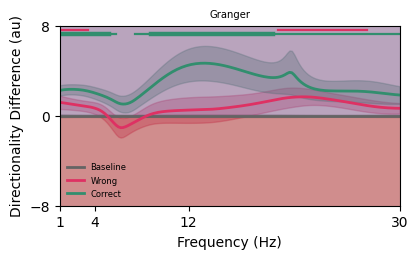

In [48]:
smooth_win = 0
plot_xlim = [1,30]
plot_xticks = [1,4,12,30]
plot_ylim = [-8,8]
figure_size = np.array((4,2.5)) * 1
plot_sigline_lw_thr1, plot_sigline_lw_thr2 = figure_size[0]*.4, figure_size[0]*.8
save_fig = 0

m_plot([granger_diff_b, granger_diff_w, granger_diff_c]
       , [color_b,color_w,color_c], error_method='sem', smooth_win=smooth_win
       , labels=['Baseline','Wrong','Correct'], plot_title=f'Granger'
       , XAxisTicks=freqs, figure_size=figure_size)

plt.plot(freqs, sigtime_diff_wb_thr1, color=color_w_n, lw=plot_sigline_lw_thr1)
plt.plot(freqs, sigtime_diff_wb_thr2, color=color_w_n, lw=plot_sigline_lw_thr2)

plt.plot(freqs, sigtime_diff_cb_thr1, color=color_c_n, lw=plot_sigline_lw_thr1)
plt.plot(freqs, sigtime_diff_cb_thr2, color=color_c_n, lw=plot_sigline_lw_thr2)

plt.fill_between([min(freqs), max(freqs)], [plot_ylim[0], plot_ylim[0]], [0, 0], color=color_ob_n, alpha=.5, edgecolor=None)
plt.fill_between([min(freqs), max(freqs)], [0, 0], [plot_ylim[1], plot_ylim[1]], color=color_mpfc_n, alpha=.5, edgecolor=None)

plt.xlabel('Frequency (Hz)')
plt.xlim(plot_xlim)
plt.xticks(plot_xticks)

plt.ylabel('Directionality Difference (au)')
plt.ylim(plot_ylim)
plt.yticks([plot_ylim[0], base_level, plot_ylim[1]])

clear_output()
if save_fig: plt.savefig(f'{FigDir}granger_diff.svg')

# Plot: Spectrum, directions

In [65]:
pval_granger_wb = np.zeros((num_dirs, freqs.shape[0])) * np.nan
pval_granger_cb = np.copy(pval_granger_wb)

for iFreq in tqdm(range(freqs.shape[0])):
    pval_granger_wb[dir_ob,iFreq]   = comp_permute_p(granger_w[:,dir_ob,iFreq], granger_b[:,dir_ob,iFreq], permute_reps=10001)
    pval_granger_wb[dir_mpfc,iFreq] = comp_permute_p(granger_w[:,dir_mpfc,iFreq], granger_b[:,dir_mpfc,iFreq], permute_reps=10001)
    
    pval_granger_cb[dir_ob,iFreq]   = comp_permute_p(granger_c[:,dir_ob,iFreq], granger_b[:,dir_ob,iFreq], permute_reps=10001)
    pval_granger_cb[dir_mpfc,iFreq] = comp_permute_p(granger_c[:,dir_mpfc,iFreq], granger_b[:,dir_mpfc,iFreq], permute_reps=10001)


  0%|          | 0/146 [00:00<?, ?it/s]

In [66]:
# Create OB SigLine

sigline_loc_ob_wb, sigline_loc_ob_cb = 9.5, 9

sigtime_ob_wb_thr1 = (pval_granger_wb[dir_ob]<sig_thresh_1).astype('float') * sigline_loc_ob_wb
sigtime_ob_wb_thr1[sigtime_ob_wb_thr1==0] = np.nan

sigtime_ob_wb_thr2 = (pval_granger_wb[dir_ob]<sig_thresh_2).astype('float') * sigline_loc_ob_wb
sigtime_ob_wb_thr2[sigtime_ob_wb_thr2==0] = np.nan

sigtime_ob_cb_thr1 = (pval_granger_cb[dir_ob]<sig_thresh_1).astype('float') * sigline_loc_ob_cb
sigtime_ob_cb_thr1[sigtime_ob_cb_thr1==0] = np.nan

sigtime_ob_cb_thr2 = (pval_granger_cb[dir_ob]<sig_thresh_2).astype('float') * sigline_loc_ob_cb
sigtime_ob_cb_thr2[sigtime_ob_cb_thr2==0] = np.nan


In [68]:
# Create mPFC SigLine

sigline_loc_mpfc_wb, sigline_loc_mpfc_cb = 9.5, 9

sigtime_mpfc_wb_thr1 = (pval_granger_wb[dir_mpfc]<sig_thresh_1).astype('float') * sigline_loc_mpfc_wb
sigtime_mpfc_wb_thr1[sigtime_mpfc_wb_thr1==0] = np.nan

sigtime_mpfc_wb_thr2 = (pval_granger_wb[dir_mpfc]<sig_thresh_2).astype('float') * sigline_loc_mpfc_wb
sigtime_mpfc_wb_thr2[sigtime_mpfc_wb_thr2==0] = np.nan

sigtime_mpfc_cb_thr1 = (pval_granger_cb[dir_mpfc]<sig_thresh_1).astype('float') * sigline_loc_mpfc_cb
sigtime_mpfc_cb_thr1[sigtime_mpfc_cb_thr1==0] = np.nan

sigtime_mpfc_cb_thr2 = (pval_granger_cb[dir_mpfc]<sig_thresh_2).astype('float') * sigline_loc_mpfc_cb
sigtime_mpfc_cb_thr2[sigtime_mpfc_cb_thr2==0] = np.nan


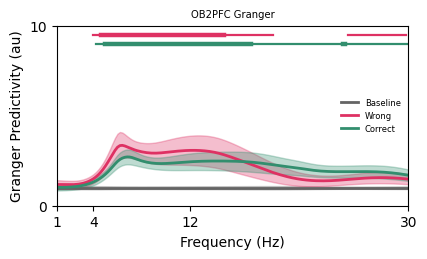

In [72]:
sel_chn = dir_ob
tmp_dir = dirs[sel_chn]
smooth_win = 0
plot_xlim = [1,30]
plot_xticks = [1,4,12,30]
plot_ylim = [0,10]
figure_size = np.array((4,2.5)) * 1
plot_sigline_lw_thr1, plot_sigline_lw_thr2 = figure_size[0]*.4, figure_size[0]*.8
save_fig = 0

m_plot([granger_b[:,sel_chn,:], granger_w[:,sel_chn,:], granger_c[:,sel_chn,:]]
       , [color_b,color_w,color_c], error_method='sem', smooth_win=smooth_win
       , labels=['Baseline','Wrong','Correct'], plot_title=f'{tmp_dir} Granger'
       , XAxisTicks=freqs, figure_size=figure_size)

plt.plot(freqs, sigtime_ob_wb_thr1, color=color_w_n, lw=plot_sigline_lw_thr1)
plt.plot(freqs, sigtime_ob_wb_thr2, color=color_w_n, lw=plot_sigline_lw_thr2)

plt.plot(freqs, sigtime_ob_cb_thr1, color=color_c_n, lw=plot_sigline_lw_thr1)
plt.plot(freqs, sigtime_ob_cb_thr2, color=color_c_n, lw=plot_sigline_lw_thr2)

plt.xlabel('Frequency (Hz)')
plt.xlim(plot_xlim)
plt.xticks(plot_xticks)

plt.ylabel('Granger Predictivity (au)')
plt.ylim(plot_ylim)
plt.yticks(plot_ylim)

clear_output()
if save_fig: plt.savefig(f'{FigDir}power_{tmp_dir.lower()}.svg')

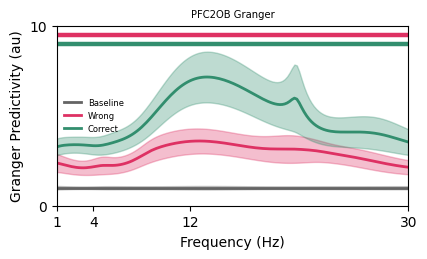

In [ ]:
sel_chn = dir_mpfc
tmp_dir = dirs[sel_chn]
smooth_win = 0
plot_xlim = [1,30]
plot_xticks = [1,4,12,30]
plot_ylim = [0,10]
figure_size = np.array((4,2.5)) * 1
plot_sigline_lw_thr1, plot_sigline_lw_thr2 = figure_size[0]*.4, figure_size[0]*.8
save_fig = 0

m_plot([granger_b[:,sel_chn,:], granger_w[:,sel_chn,:], granger_c[:,sel_chn,:]]
       , [color_b,color_w,color_c], error_method='sem', smooth_win=smooth_win
       , labels=['Baseline','Wrong','Correct'], plot_title=f'{tmp_dir} Granger'
       , XAxisTicks=freqs, figure_size=figure_size)

plt.plot(freqs, sigtime_mpfc_wb_thr1, color=color_w_n, lw=plot_sigline_lw_thr1)
plt.plot(freqs, sigtime_mpfc_wb_thr2, color=color_w_n, lw=plot_sigline_lw_thr2)

plt.plot(freqs, sigtime_mpfc_cb_thr1, color=color_c_n, lw=plot_sigline_lw_thr1)
plt.plot(freqs, sigtime_mpfc_cb_thr2, color=color_c_n, lw=plot_sigline_lw_thr2)

plt.xlabel('Frequency (Hz)')
plt.xlim(plot_xlim)
plt.xticks(plot_xticks)

plt.ylabel('Granger Predictivity (au)')
plt.ylim(plot_ylim)
plt.yticks(plot_ylim)

clear_output()
if save_fig: plt.savefig(f'{FigDir}power_{tmp_dir.lower()}.svg')

# Effect size

In [6]:
dprime_wb = np.zeros((num_dirs,freqs.shape[0])) * np.nan
dprime_cb, dprime_cw = np.copy(dprime_wb), np.copy(dprime_wb)

for iFreq in range(freqs.shape[0]):
    dprime_wb[dir_ob,iFreq] = compute_dprime(granger_w[:,dir_ob,iFreq], granger_b[:,dir_ob,iFreq])
    dprime_cb[dir_ob,iFreq] = compute_dprime(granger_c[:,dir_ob,iFreq], granger_b[:,dir_ob,iFreq])
    dprime_cw[dir_ob,iFreq] = compute_dprime(granger_c[:,dir_ob,iFreq], granger_w[:,dir_ob,iFreq])

    dprime_wb[dir_mpfc,iFreq] = compute_dprime(granger_w[:,dir_mpfc,iFreq], granger_b[:,dir_mpfc,iFreq])
    dprime_cb[dir_mpfc,iFreq] = compute_dprime(granger_c[:,dir_mpfc,iFreq], granger_b[:,dir_mpfc,iFreq])
    dprime_cw[dir_mpfc,iFreq] = compute_dprime(granger_c[:,dir_mpfc,iFreq], granger_w[:,dir_mpfc,iFreq])

    dprime_wb[dir_diff,iFreq] = compute_dprime(granger_diff_w[:,iFreq], granger_diff_b[:,iFreq])
    dprime_cb[dir_diff,iFreq] = compute_dprime(granger_diff_c[:,iFreq], granger_diff_b[:,iFreq])
    dprime_cw[dir_diff,iFreq] = compute_dprime(granger_diff_c[:,iFreq], granger_diff_w[:,iFreq])


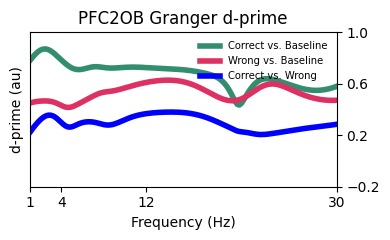

In [7]:
sel_chn = dir_mpfc
tmp_region = dirs[sel_chn]
smooth_win = 0
plot_xlim = [1,30]
plot_ylim = [-.2,1]
plot_xticks = [1,4,12,30]
plot_yticks = [min(plot_ylim),.2,.6,max(plot_ylim)]
figure_size = np.array((4,2.5)) * 1
plot_lw = figure_size[0]*1
save_fig = 0

plt.figure(figsize=figure_size)

plt.plot(freqs, dprime_cb[sel_chn], color=color_c_n, lw=plot_lw, label="Correct vs. Baseline")
plt.plot(freqs, dprime_wb[sel_chn], color=color_w_n, lw=plot_lw, label="Wrong vs. Baseline")
plt.plot(freqs, dprime_cw[sel_chn], color='b', lw=plot_lw, label="Correct vs. Wrong")

plt.xlabel('Frequency (Hz)')
plt.xlim(plot_xlim)
plt.xticks(plot_xticks)

plt.ylabel('d-prime (au)')
plt.ylim(plot_ylim)
plt.yticks(plot_yticks)

plt.tick_params(axis='y', left=False, right=True)
plt.tick_params(axis='y', labelleft=False, labelright=True)
plt.title(f'{tmp_region} Granger d-prime')
plt.tight_layout()
plt.legend(frameon=False, ncol=1, loc='upper right', fontsize=figure_size[0]*1.8)

clear_output()
if save_fig: plt.savefig(f'{FigDir}granger_dprime_{tmp_region}.svg')

In [11]:
sel_chn = dir_mpfc

print(f"CB -> All Freqs: d-prime -> mean: {np.nanmean(dprime_cb[sel_chn]).round(2)} | "
      f"range: {min(dprime_cb[sel_chn]).round(2)} - {max(dprime_cb[sel_chn]).round(2)}")
print(f"WB -> All Freqs: d-prime -> mean: {np.nanmean(dprime_wb[sel_chn]).round(2)} | "
      f"range: {min(dprime_wb[sel_chn]).round(2)} - {max(dprime_wb[sel_chn]).round(2)}")
print(f"CW -> All Freqs: d-prime -> mean: {np.nanmean(dprime_cw[sel_chn]).round(2)} | "
      f"range: {min(dprime_cw[sel_chn]).round(2)} - {max(dprime_cw[sel_chn]).round(2)}")
print(f"----------")


CB -> All Freqs: d-prime -> mean: 0.67 | range: 0.43 - 0.87
WB -> All Freqs: d-prime -> mean: 0.53 | range: 0.42 - 0.63
CW -> All Freqs: d-prime -> mean: 0.3 | range: 0.21 - 0.38
----------


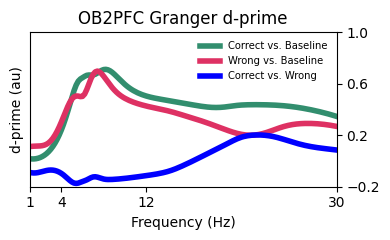

In [33]:
sel_chn = dir_ob
tmp_region = dirs[sel_chn]
smooth_win = 0
plot_xlim = [1,30]
plot_ylim = [-.2,1]
plot_xticks = [1,4,12,30]
plot_yticks = [min(plot_ylim),.2,.6,max(plot_ylim)]
figure_size = np.array((4,2.5)) * 1
plot_lw = figure_size[0]*1
save_fig = 0

plt.figure(figsize=figure_size)

plt.plot(freqs, dprime_cb[sel_chn], color=color_c_n, lw=plot_lw, label="Correct vs. Baseline")
plt.plot(freqs, dprime_wb[sel_chn], color=color_w_n, lw=plot_lw, label="Wrong vs. Baseline")
plt.plot(freqs, dprime_cw[sel_chn], color='b', lw=plot_lw, label="Correct vs. Wrong")

plt.xlabel('Frequency (Hz)')
plt.xlim(plot_xlim)
plt.xticks(plot_xticks)

plt.ylabel('d-prime (au)')
plt.ylim(plot_ylim)
plt.yticks(plot_yticks)

plt.tick_params(axis='y', left=False, right=True)
plt.tick_params(axis='y', labelleft=False, labelright=True)
plt.title(f'{tmp_region} Granger d-prime')
plt.tight_layout()
plt.legend(frameon=False, ncol=1, loc='upper right', fontsize=figure_size[0]*1.8)

clear_output()
if save_fig: plt.savefig(f'{FigDir}granger_dprime_{tmp_region}.svg')

In [25]:
sel_chn = dir_ob

print(f"CB -> Delta: d-prime -> mean: {np.nanmean(dprime_cb[sel_chn, idx_band_delta]).round(2)} | "
      f"range: {min(dprime_cb[sel_chn, idx_band_delta]).round(2)} - {max(dprime_cb[sel_chn, idx_band_delta]).round(2)}")
print(f"CB -> Theta: d-prime -> mean: {np.nanmean(dprime_cb[sel_chn, idx_band_theta]).round(2)} | "
      f"range: {min(dprime_cb[sel_chn, idx_band_theta]).round(2)} - {max(dprime_cb[sel_chn, idx_band_theta]).round(2)}")
print(f"CB -> Beta: d-prime -> mean: {np.nanmean(dprime_cb[sel_chn, idx_band_beta]).round(2)} | "
      f"range: {min(dprime_cb[sel_chn, idx_band_beta]).round(2)} - {max(dprime_cb[sel_chn, idx_band_beta]).round(2)}")
print(f"----------")

print(f"WB -> Delta: d-prime -> mean: {np.nanmean(dprime_wb[sel_chn, idx_band_delta]).round(2)} | "
      f"range: {min(dprime_wb[sel_chn, idx_band_delta]).round(2)} - {max(dprime_wb[sel_chn, idx_band_delta]).round(2)}")
print(f"WB -> Theta: d-prime -> mean: {np.nanmean(dprime_wb[sel_chn, idx_band_theta]).round(2)} | "
      f"range: {min(dprime_wb[sel_chn, idx_band_theta]).round(2)} - {max(dprime_wb[sel_chn, idx_band_theta]).round(2)}")
print(f"WB -> Beta: d-prime -> mean: {np.nanmean(dprime_wb[sel_chn, idx_band_beta]).round(2)} | "
      f"range: {min(dprime_wb[sel_chn, idx_band_beta]).round(2)} - {max(dprime_wb[sel_chn, idx_band_beta]).round(2)}")
print(f"----------")

print(f"CW -> All Freq: d-prime -> mean: {np.nanmean(dprime_cw[sel_chn]).round(2)} | "
      f"range: {min(dprime_cw[sel_chn]).round(2)} - {max(dprime_cw[sel_chn]).round(2)}")
print(f"----------")


CB -> Delta: d-prime -> mean: 0.08 | range: 0.02 - 0.24
CB -> Theta: d-prime -> mean: 0.59 | range: 0.28 - 0.71
CB -> Beta: d-prime -> mean: 0.43 | range: 0.35 - 0.5
----------
WB -> Delta: d-prime -> mean: 0.16 | range: 0.11 - 0.3
WB -> Theta: d-prime -> mean: 0.53 | range: 0.34 - 0.7
WB -> Beta: d-prime -> mean: 0.29 | range: 0.2 - 0.42
----------
CW -> All Freq: d-prime -> mean: 0.0 | range: -0.17 - 0.2
----------


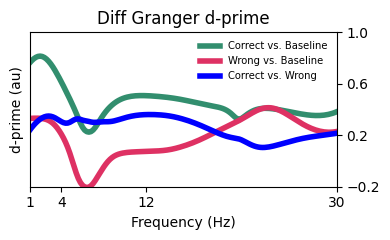

In [35]:
sel_chn = dir_diff
tmp_region = dirs[sel_chn]
smooth_win = 0
plot_xlim = [1,30]
plot_ylim = [-.2,1]
plot_xticks = [1,4,12,30]
plot_yticks = [min(plot_ylim),.2,.6,max(plot_ylim)]
figure_size = np.array((4,2.5)) * 1
plot_lw = figure_size[0]*1
save_fig = 0

plt.figure(figsize=figure_size)

plt.plot(freqs, dprime_cb[sel_chn], color=color_c_n, lw=plot_lw, label="Correct vs. Baseline")
plt.plot(freqs, dprime_wb[sel_chn], color=color_w_n, lw=plot_lw, label="Wrong vs. Baseline")
plt.plot(freqs, dprime_cw[sel_chn], color='b', lw=plot_lw, label="Correct vs. Wrong")

plt.xlabel('Frequency (Hz)')
plt.xlim(plot_xlim)
plt.xticks(plot_xticks)

plt.ylabel('d-prime (au)')
plt.ylim(plot_ylim)
plt.yticks(plot_yticks)

plt.tick_params(axis='y', left=False, right=True)
plt.tick_params(axis='y', labelleft=False, labelright=True)
plt.title(f'{tmp_region} Granger d-prime')
plt.tight_layout()
plt.legend(frameon=False, ncol=1, loc='upper right', fontsize=figure_size[0]*1.8)

clear_output()
if save_fig: plt.savefig(f'{FigDir}granger_dprime_{tmp_region}.svg')

In [35]:
sel_chn = dir_diff
idx_band_LT = np.where((freqs>4) & (freqs<=8))[0]
idx_band_Lbeta = np.where((freqs>12) & (freqs<=18))[0]
idx_band_Hbeta = np.where((freqs>24) & (freqs<=30))[0]

print(f"CB -> Delta: d-prime -> mean: {np.nanmean(dprime_cb[sel_chn, idx_band_delta]).round(2)} | "
      f"range: {min(dprime_cb[sel_chn, idx_band_delta]).round(2)} - {max(dprime_cb[sel_chn, idx_band_delta]).round(2)}")
print(f"CB -> Theta: d-prime -> mean: {np.nanmean(dprime_cb[sel_chn, idx_band_theta]).round(2)} | "
      f"range: {min(dprime_cb[sel_chn, idx_band_theta]).round(2)} - {max(dprime_cb[sel_chn, idx_band_theta]).round(2)}")
print(f"CB -> Beta: d-prime -> mean: {np.nanmean(dprime_cb[sel_chn, idx_band_beta]).round(2)} | "
      f"range: {min(dprime_cb[sel_chn, idx_band_beta]).round(2)} - {max(dprime_cb[sel_chn, idx_band_beta]).round(2)}")
print(f"* CB -> All Freqs: d-prime -> mean: {np.nanmean(dprime_cb[sel_chn]).round(2)} | "
      f"range: {min(dprime_cb[sel_chn]).round(2)} - {max(dprime_cb[sel_chn]).round(2)}")
print(f"* CB -> Low Theta: d-prime -> mean: {np.nanmean(dprime_cb[sel_chn, idx_band_LT]).round(2)} | "
      f"range: {min(dprime_cb[sel_chn, idx_band_LT]).round(2)} - {max(dprime_cb[sel_chn, idx_band_LT]).round(2)}")
print(f"----------")

print(f"WB -> Delta: d-prime -> mean: {np.nanmean(dprime_wb[sel_chn, idx_band_delta]).round(2)} | "
      f"range: {min(dprime_wb[sel_chn, idx_band_delta]).round(2)} - {max(dprime_wb[sel_chn, idx_band_delta]).round(2)}")
print(f"WB -> Theta: d-prime -> mean: {np.nanmean(dprime_wb[sel_chn, idx_band_theta]).round(2)} | "
      f"range: {min(dprime_wb[sel_chn, idx_band_theta]).round(2)} - {max(dprime_wb[sel_chn, idx_band_theta]).round(2)}")
print(f"WB -> Beta: d-prime -> mean: {np.nanmean(dprime_wb[sel_chn, idx_band_beta]).round(2)} | "
      f"range: {min(dprime_wb[sel_chn, idx_band_beta]).round(2)} - {max(dprime_wb[sel_chn, idx_band_beta]).round(2)}")
print(f"* WB -> High Beta: d-prime -> mean: {np.nanmean(dprime_wb[sel_chn, idx_band_Hbeta]).round(2)} | "
      f"range: {min(dprime_wb[sel_chn, idx_band_Hbeta]).round(2)} - {max(dprime_wb[sel_chn, idx_band_Hbeta]).round(2)}")
print(f"----------")

print(f"CW -> Delta: d-prime -> mean: {np.nanmean(dprime_cw[sel_chn, idx_band_delta]).round(2)} | "
      f"range: {min(dprime_cw[sel_chn, idx_band_delta]).round(2)} - {max(dprime_cw[sel_chn, idx_band_delta]).round(2)}")
print(f"CW -> Theta: d-prime -> mean: {np.nanmean(dprime_cw[sel_chn, idx_band_theta]).round(2)} | "
      f"range: {min(dprime_cw[sel_chn, idx_band_theta]).round(2)} - {max(dprime_cw[sel_chn, idx_band_theta]).round(2)}")
print(f"CW -> Beta: d-prime -> mean: {np.nanmean(dprime_cw[sel_chn, idx_band_beta]).round(2)} | "
      f"range: {min(dprime_cw[sel_chn, idx_band_beta]).round(2)} - {max(dprime_cw[sel_chn, idx_band_beta]).round(2)}")
print(f"* CW -> Low Beta: d-prime -> mean: {np.nanmean(dprime_cw[sel_chn, idx_band_Lbeta]).round(2)} | "
      f"range: {min(dprime_cw[sel_chn, idx_band_Lbeta]).round(2)} - {max(dprime_cw[sel_chn, idx_band_Lbeta]).round(2)}")
print(f"----------")

CB -> Delta: d-prime -> mean: 0.76 | range: 0.61 - 0.82
CB -> Theta: d-prime -> mean: 0.41 | range: 0.22 - 0.58
CB -> Beta: d-prime -> mean: 0.41 | range: 0.32 - 0.51
* CB -> All Freqs: d-prime -> mean: 0.45 | range: 0.22 - 0.82
* CB -> Low Theta: d-prime -> mean: 0.35 | range: 0.22 - 0.58
----------
WB -> Delta: d-prime -> mean: 0.3 | range: 0.21 - 0.33
WB -> Theta: d-prime -> mean: -0.01 | range: -0.21 - 0.18
WB -> Beta: d-prime -> mean: 0.25 | range: 0.07 - 0.41
* WB -> High Beta: d-prime -> mean: 0.29 | range: 0.22 - 0.41
----------
CW -> Delta: d-prime -> mean: 0.32 | range: 0.24 - 0.35
CW -> Theta: d-prime -> mean: 0.32 | range: 0.29 - 0.36
CW -> Beta: d-prime -> mean: 0.22 | range: 0.1 - 0.36
* CW -> Low Beta: d-prime -> mean: 0.32 | range: 0.25 - 0.36
----------
